# 5. GOTOBI EFFECT · DARWINEX REPLICATION (USDJPY)

Does the Gotobi edge validated on **Axi** (full history) carry over to **Darwinex** (short sample: 2025-07-02 → 2026-11-04)?

The Darwinex sample is too short (~95 trades) to re-test the edge statistically, so this notebook does **not** re-prove it. It answers three narrower questions:

1. **Same trade?** Same dates, same prices, same gross P&L on both feeds (paired comparison).
2. **What does Darwinex cost?** Real spread + commission, by season, with a break-even spread sweep.
3. **Is the Darwinex window typical of the Axi history?** Placebo, random-date test, intraday profile and where this window sits in the Axi series.

Plus two clearly labelled extras: an **exploratory** spread filter (a new hypothesis, not adopted) and sizing/risk at the declared fraction.

**Self-contained:** only needs `gotobi_engine.py` (v1.0) and the two CSVs. No `variant_config` / `gotobi_utils` dependency.

## 0. CONFIG

In [1]:
# ============================ CONFIG (edit here only) ============================
ENGINE_DIR = None   # None = search cwd/parents for gotobi_engine.py; or e.g. "02_strategy_development/Gotobi"
AXI_CSV = "data/axi/usdjpy_M5_200001022200_202611030050.csv"
DWX_CSV = "data/darwinex/usdjpy_M5_202507022000_202611041220.csv"
START = "2025-07-02"            # common window = first Darwinex bar
AXI_FULL_START = "2017-01-01"   # None = skip sections 6 and 7b (long Axi history)

# costs: Axi scale 0.7 is the placeholder of the v1 variant; Darwinex feed is the real spread
SCALE_AXI, COMM_AXI = 0.7, 0.0
SCALE_DWX, COMM_DWX = 1.0, 0.25  # 2.5 USD/lot per deal on 100k USD ~ 0.25 bps per side (CHECK: per side or round trip)
CTX_FLAT_PIPS = 1.0              # flat spread used only for the long-history context (feed spread is not real before 2021)
ZERO_FLOOR_PIPS = 0.3            # sensitivity for bars with feed spread = 0

# risk (Axi Select numbers; Darwinex needs its own limit, see section 8)
CAPITAL, FRAC, HARD = 10_000, 2.5, 0.09

# replication gates, declared BEFORE running this notebook
CORR_MIN, MAX_MEAN_DIFF_BPS, MAX_SD_DIFF_BPS = 0.99, 0.5, 2.0

N_PERM, SEED = 5000, 42
WRITE_OUTPUTS = True            # writes trades CSV + summary JSON under <engine dir>/runs/
WRITE_YAML = False              # writes a DRAFT variants/v2_darwinex_usdjpy.yaml (verify variant_config supports the fields)

In [2]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

def find_engine_dir(start=None):
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        for cand in (base, *base.glob("*"), *base.glob("*/*")):
            if cand.is_dir() and (cand / "gotobi_engine.py").is_file():
                return cand
    raise FileNotFoundError("gotobi_engine.py not found near " + str(here) + ". Set ENGINE_DIR in the CONFIG cell.")

EDGE_DIR = Path(ENGINE_DIR).resolve() if ENGINE_DIR else find_engine_dir()
if str(EDGE_DIR) not in sys.path:
    sys.path.insert(0, str(EDGE_DIR))
import gotobi_engine as eng

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "legend.frameon": False, "figure.autolayout": True})
AXI_C, DWX_C, GREEN, RED, GREY = "#2b6cb0", "#d9822b", "#2f855a", "#c53030", "#718096"
SEAS_C = {"winter": "#4a5568", "summer": "#d69e2e"}
COL = {"axi": AXI_C, "dwx": DWX_C}
NAME = {"axi": "Axi (scale 0.7)", "dwx": "Darwinex (real spread + comm.)"}
PIP = eng.ENGINE_DEFAULTS["pip_size"]
print("engine dir:", EDGE_DIR)

engine dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi


## 1. DATA AND ENGINE DECISIONS
Both feeds are cut to the common window, run through the same engine, and checked with the engine's own quality gate.

,first_bar,last_bar,bars,gotobi_dates,trades
axi,2025-07-02 00:00:00,2026-11-02 22:50:00,99863,96,95
dwx,2025-07-02 17:00:00,2026-11-02 22:50:00,99490,96,95


,weeks,weekly_ok_share,weekly_structure,no_rollover,constant_window,no_overlap,mtm_reconciles,trades_per_year,entry_is_2230_utc,all_ok
axi,70,1.0,True,True,True,True,True,True,True,True
dwx,70,1.0,True,True,True,True,True,True,True,True


,axi,dwx
engine decision,,
ok,95,95
no entry bar,1,1


dates only in Axi: none | only in Darwinex: none


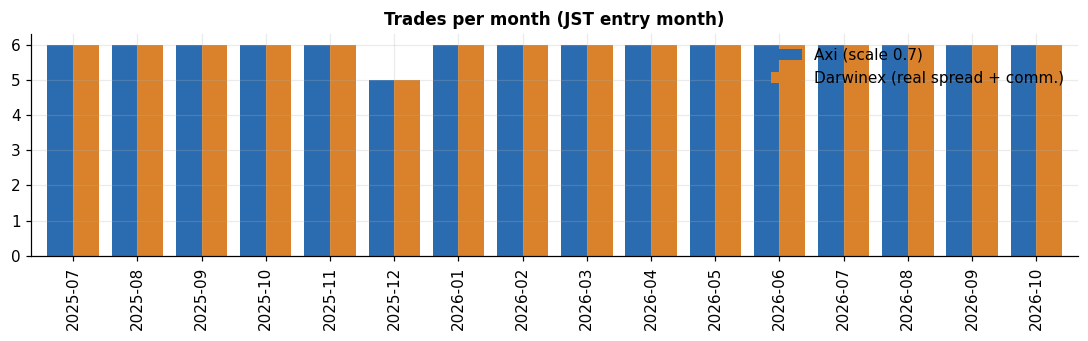

In [3]:
eng.apply_cfd_preset("axi_usdjpy")          # same contract spec on both: 100k, min lot 0.01
raw = {"axi": eng.load_data(csv_path=AXI_CSV, start=START, verbose=False),
       "dwx": eng.load_data(csv_path=DWX_CSV, start=START, verbose=False)}
END = min(d.index[-1] for d in raw.values())
DF = {k: d[d.index <= END] for k, d in raw.items()}
BT = {"axi": dict(spread_scale=SCALE_AXI, commission_bps_per_side=COMM_AXI),
      "dwx": dict(spread_scale=SCALE_DWX, commission_bps_per_side=COMM_DWX)}
TR = {k: eng.run_gotobi_backtest(DF[k], **BT[k]) for k in DF}
SIG = {k: eng.signal_table(DF[k], spread_scale=BT[k]["spread_scale"]) for k in DF}
ET, XT = eng.ENGINE_DEFAULTS["entry_time"], eng.ENGINE_DEFAULTS["exit_time"]

info = pd.DataFrame({k: dict(first_bar=DF[k].index[0], last_bar=DF[k].index[-1], bars=len(DF[k]),
                             gotobi_dates=len(SIG[k]), trades=len(TR[k])) for k in DF}).T
display(info)

chk = {}
for k in DF:
    wk, val = eng.check_weekly_structure(DF[k]), eng.validate(DF[k], TR[k])
    chk[k] = dict(weeks=wk["weeks"], weekly_ok_share=wk["ok_share"], **val)
display(pd.DataFrame(chk).T)
display(pd.DataFrame({k: SIG[k]["reason"].value_counts() for k in SIG}).fillna(0).astype(int).rename_axis("engine decision"))

da, dd_ = set(TR["axi"]["entry_date"]), set(TR["dwx"]["entry_date"])
print("dates only in Axi:", sorted(da - dd_) or "none", "| only in Darwinex:", sorted(dd_ - da) or "none")

fig, ax = plt.subplots(figsize=(10, 3.2))
m = pd.DataFrame({k: TR[k].groupby(pd.to_datetime(TR[k]["entry_date"]).dt.to_period("M")).size() for k in TR}).fillna(0)
m.index = m.index.astype(str)
m.plot.bar(ax=ax, color=[COL[k] for k in m.columns], width=.8)
ax.set_title("Trades per month (JST entry month)"); ax.set_xlabel(""); ax.legend([NAME[k] for k in m.columns])
plt.show()

## 2. PAIRED COMPARISON · GROSS P&L AND RAW PRICES
Same date, same window, no costs: if the two feeds saw the same market, gross P&L must be (almost) identical. This is the real replication test.

,"Darwinex - Axi, gross bps"
n,95.000000
corr,0.998789
mean_diff_bps,-0.013599
sd_diff_bps,0.694774
se_diff_bps,0.071282
t_mean_diff,-0.190770
max_abs_diff_bps,3.163520
loa_lo,-1.375356
loa_hi,1.348159


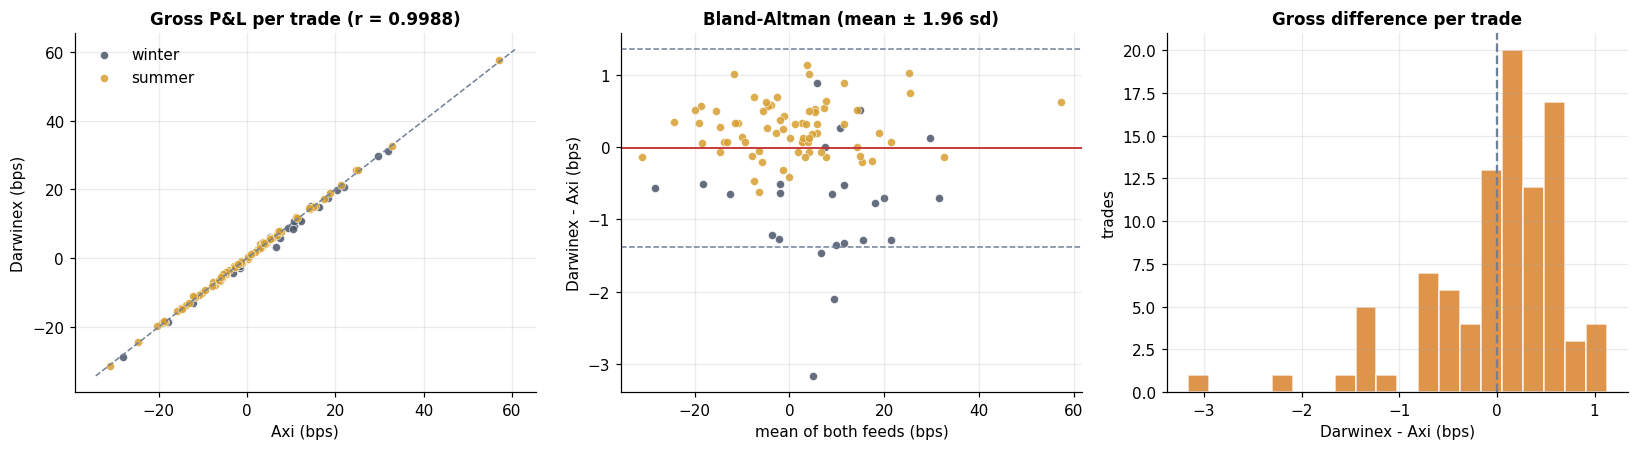

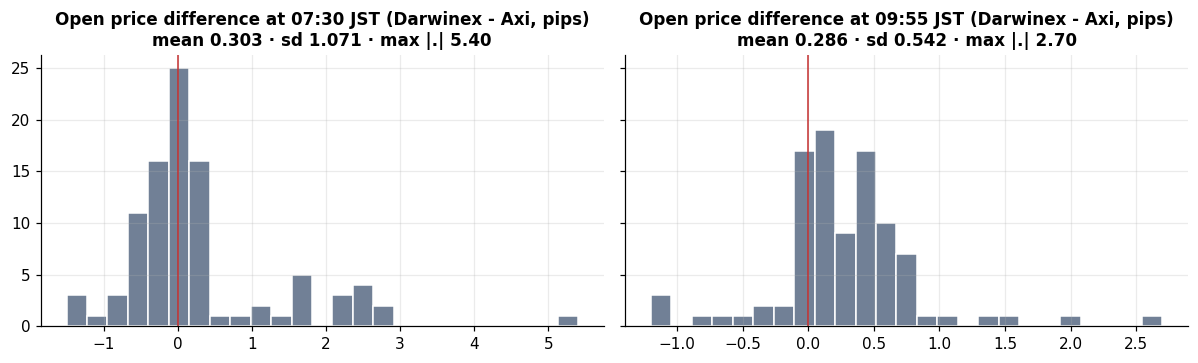

,label,season,gross_axi,gross_dwx,diff,spread_axi,spread_dwx
entry_date,,,,,,,
2025-12-05,5,winter,6.52,3.35,-3.16,5.04,2.7
2026-02-13,15,winter,10.48,8.38,-2.10,7.00,8.9
2025-11-20,20,winter,7.45,5.98,-1.47,5.04,1.7
2025-11-14,15,winter,10.62,9.26,-1.36,5.04,3.1
2026-01-23,25,winter,12.13,10.80,-1.33,5.04,1.9
2025-12-30,EOM,winter,21.99,20.71,-1.29,5.53,4.7
2025-11-28,EOM,winter,16.19,14.91,-1.28,5.04,2.0
2025-11-25,25,winter,-1.53,-2.80,-1.27,5.04,2.8


In [4]:
T = {k: TR[k].set_index(pd.to_datetime(TR[k]["entry_date"])) for k in TR}
for k in T:
    T[k]["season"] = SIG[k]["season"].reindex(T[k].index)
J = pd.concat({"label": T["axi"]["label"], "season": T["axi"]["season"],
               "gross_axi": T["axi"]["pnl_gross_bps"], "gross_dwx": T["dwx"]["pnl_gross_bps"],
               "net_axi": T["axi"]["pnl_bps"], "net_dwx": T["dwx"]["pnl_bps"],
               "spread_axi": T["axi"]["spread_pips"], "spread_dwx": T["dwx"]["spread_pips"]}, axis=1)
pair = J.dropna(subset=["gross_axi", "gross_dwx"])
D = pair["gross_dwx"] - pair["gross_axi"]
PAIR = dict(n=len(pair), corr=float(pair[["gross_axi", "gross_dwx"]].corr().iloc[0, 1]), mean_diff_bps=float(D.mean()),
            sd_diff_bps=float(D.std(ddof=1)), se_diff_bps=float(D.std(ddof=1) / np.sqrt(len(D))),
            t_mean_diff=float(D.mean() / (D.std(ddof=1) / np.sqrt(len(D)))), max_abs_diff_bps=float(D.abs().max()),
            loa_lo=float(D.mean() - 1.96 * D.std(ddof=1)), loa_hi=float(D.mean() + 1.96 * D.std(ddof=1)))
display(pd.Series(PAIR, name="Darwinex - Axi, gross bps").to_frame())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for s, c in SEAS_C.items():
    mk = pair["season"] == s
    ax[0].scatter(pair["gross_axi"][mk], pair["gross_dwx"][mk], s=28, color=c, alpha=.85, label=s, edgecolor="white", linewidth=.4)
    ax[1].scatter((pair["gross_axi"] + pair["gross_dwx"])[mk] / 2, D[mk], s=28, color=c, alpha=.85, label=s, edgecolor="white", linewidth=.4)
lo, hi = pair[["gross_axi", "gross_dwx"]].min().min() - 3, pair[["gross_axi", "gross_dwx"]].max().max() + 3
ax[0].plot([lo, hi], [lo, hi], color=GREY, ls="--", lw=1)
ax[0].set(title=f"Gross P&L per trade (r = {PAIR['corr']:.4f})", xlabel="Axi (bps)", ylabel="Darwinex (bps)"); ax[0].legend()
ax[1].axhline(PAIR["mean_diff_bps"], color=RED, lw=1.2)
for v in (PAIR["loa_lo"], PAIR["loa_hi"]):
    ax[1].axhline(v, color=GREY, ls="--", lw=1)
ax[1].set(title="Bland-Altman (mean ± 1.96 sd)", xlabel="mean of both feeds (bps)", ylabel="Darwinex - Axi (bps)")
ax[2].hist(D, bins=20, color=DWX_C, alpha=.85, edgecolor="white"); ax[2].axvline(0, color=GREY, ls="--")
ax[2].set(title="Gross difference per trade", xlabel="Darwinex - Axi (bps)", ylabel="trades")
plt.show()

gA, gD = eng.price_grid(DF["axi"], pair.index, [ET, XT]), eng.price_grid(DF["dwx"], pair.index, [ET, XT])
pdiff = (gD - gA) / PIP
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, t_ in zip(ax, (ET, XT)):
    a.hist(pdiff[t_].dropna(), bins=25, color=GREY, edgecolor="white")
    a.set_title(f"Open price difference at {t_} JST (Darwinex - Axi, pips)\nmean {pdiff[t_].mean():.3f} · sd {pdiff[t_].std():.3f} · max |.| {pdiff[t_].abs().max():.2f}")
    a.axvline(0, color=RED, lw=1)
plt.show()

out = pair.assign(diff=D, abs_diff=D.abs()).sort_values("abs_diff", ascending=False).head(8)
display(out[["label", "season", "gross_axi", "gross_dwx", "diff", "spread_axi", "spread_dwx"]].round(2))

## 3. COSTS · DARWINEX VS AXI
Cost per trade = spread paid at entry (exit at bid, one spread per round trip) + commission (both deals). Axi spread uses the 0.7 **placeholder** scale, so only the Darwinex cost is a measurement.

,gross,spread,commission,other,net,cost_total,cost_share_of_gross
axi,2.290,1.094,0.0,0.001,1.196,1.094,0.478
dwx,2.277,0.790,0.5,0.001,0.986,1.290,0.567


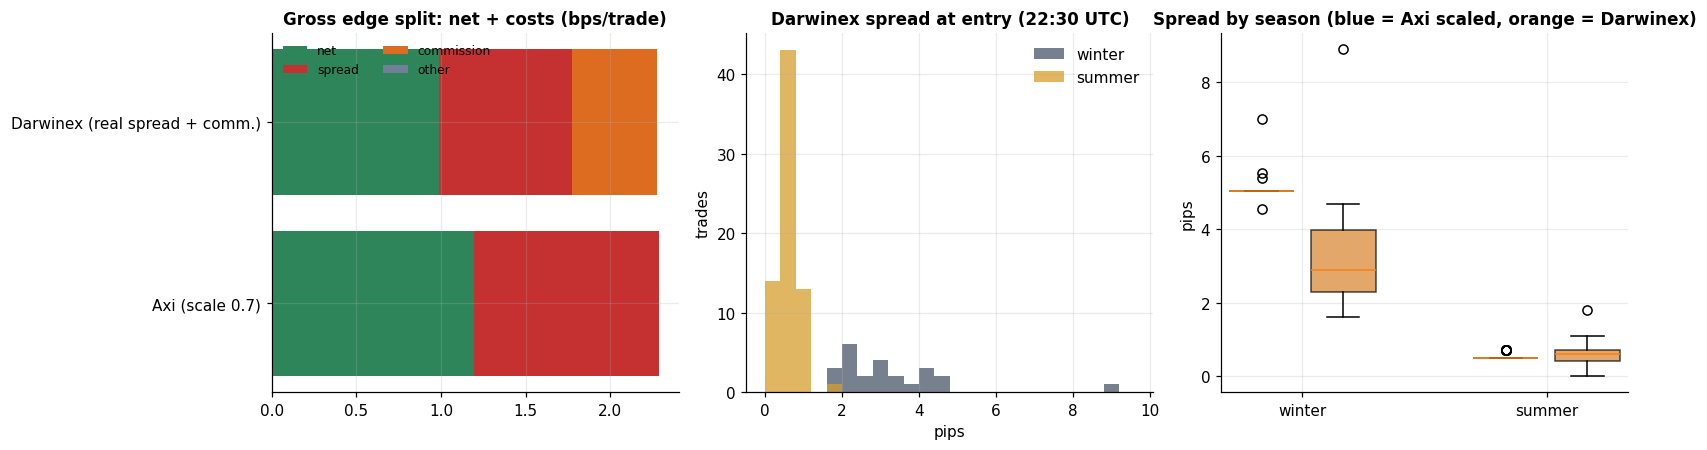

Darwinex trades with feed spread = 0: 4 of 95. If those really paid 0.3 pips the net mean falls by ~0.008 bps/trade.


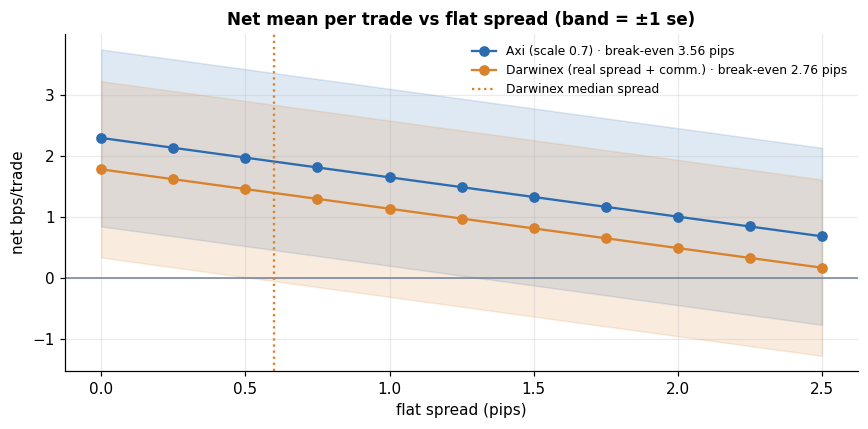

{'axi': 3.56, 'dwx': 2.76} pips break-even | Darwinex mean spread paid: 1.23 pips


In [5]:
dec = {}
for k in TR:
    tr = TR[k]
    sp = tr["spread_pips"] * PIP / tr["entry_price"] * 1e4
    comm = 2 * BT[k]["commission_bps_per_side"]
    dec[k] = dict(gross=tr["pnl_gross_bps"].mean(), spread=sp.mean(), commission=comm,
                  other=(tr["cost_bps"] - sp - comm).mean(), net=tr["pnl_bps"].mean())
dec = pd.DataFrame(dec).T
dec["cost_total"] = dec["spread"] + dec["commission"] + dec["other"]
dec["cost_share_of_gross"] = dec["cost_total"] / dec["gross"]
display(dec.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
y = np.arange(2)
parts = [("net", GREEN), ("spread", RED), ("commission", "#dd6b20"), ("other", GREY)]
left = np.zeros(2)
for p, c in parts:
    v = dec.loc[["axi", "dwx"], p].to_numpy(float)
    ax[0].barh(y, v, left=left, color=c, label=p); left += v
ax[0].set_yticks(y); ax[0].set_yticklabels([NAME["axi"], NAME["dwx"]]); ax[0].legend(ncol=2, fontsize=8)
ax[0].set_title("Gross edge split: net + costs (bps/trade)")

for s, c in SEAS_C.items():
    ax[1].hist(T["dwx"].loc[T["dwx"]["season"] == s, "spread_pips"], bins=np.arange(0, 10, .4), alpha=.75, color=c, label=s)
ax[1].set(title="Darwinex spread at entry (22:30 UTC)", xlabel="pips", ylabel="trades"); ax[1].legend()

pos, data, cols = [], [], []
for i, s in enumerate(["winter", "summer"]):
    for j, k in enumerate(["axi", "dwx"]):
        pos.append(i * 3 + j); data.append(T[k].loc[T[k]["season"] == s, "spread_pips"].dropna().to_numpy()); cols.append(COL[k])
bp = ax[2].boxplot(data, positions=pos, widths=.8, patch_artist=True, showfliers=True)
for b, c in zip(bp["boxes"], cols):
    b.set_facecolor(c); b.set_alpha(.7)
ax[2].set_xticks([.5, 3.5]); ax[2].set_xticklabels(["winter", "summer"]); ax[2].set_title("Spread by season (blue = Axi scaled, orange = Darwinex)"); ax[2].set_ylabel("pips")
plt.show()

n0 = int((TR["dwx"]["spread_pips"] <= 0).sum())
fix = n0 * ZERO_FLOOR_PIPS * PIP / TR["dwx"]["entry_price"].mean() * 1e4 / len(TR["dwx"])
print(f"Darwinex trades with feed spread = 0: {n0} of {len(TR['dwx'])}. If those really paid {ZERO_FLOOR_PIPS} pips the net mean falls by ~{fix:.3f} bps/trade.")

SWEEP = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]
def sweep(df, comm):
    rows = []
    for s in SWEEP:
        x = eng.run_gotobi_backtest(df, cost_mode="flat_pips", flat_spread_pips=s, commission_bps_per_side=comm)["pnl_bps"]
        rows.append((s, x.mean(), x.std(ddof=1) / np.sqrt(len(x))))
    return pd.DataFrame(rows, columns=["pips", "net_bps", "se"])
def breakeven(sw):
    a, b = np.polyfit(sw["pips"], sw["net_bps"], 1)
    return float(-b / a) if a < 0 else np.nan
SW = {"axi": sweep(DF["axi"], COMM_AXI), "dwx": sweep(DF["dwx"], COMM_DWX)}
BE = {k: breakeven(SW[k]) for k in SW}
fig, ax = plt.subplots(figsize=(8, 4))
for k in SW:
    ax.plot(SW[k]["pips"], SW[k]["net_bps"], marker="o", color=COL[k], label=f"{NAME[k]} · break-even {BE[k]:.2f} pips")
    ax.fill_between(SW[k]["pips"], SW[k]["net_bps"] - SW[k]["se"], SW[k]["net_bps"] + SW[k]["se"], color=COL[k], alpha=.15)
ax.axhline(0, color=GREY, lw=1)
ax.axvline(TR["dwx"]["spread_pips"].median(), color=DWX_C, ls=":", label="Darwinex median spread")
ax.set(title="Net mean per trade vs flat spread (band = ±1 se)", xlabel="flat spread (pips)", ylabel="net bps/trade"); ax.legend(fontsize=8)
plt.show()
print({k: round(v, 2) for k, v in BE.items()}, "pips break-even | Darwinex mean spread paid:", round(TR["dwx"]["spread_pips"].mean(), 2), "pips")

## 4. RESULTS · DARWINEX WINDOW
Small sample: read the t-statistics as descriptive, not as evidence for or against the edge.

,n,mean_bps,median_bps,std_bps,t,p_one,pf,win_rate,sum_bps
axi gross,95.0,2.290,2.869,14.099,1.583,0.057,1.539,0.579,217.566
axi net,95.0,1.196,2.289,13.869,0.840,0.200,1.260,0.558,113.592
dwx gross,95.0,2.277,2.993,14.046,1.580,0.057,1.539,0.568,216.274
dwx net,95.0,0.986,1.923,13.880,0.693,0.244,1.210,0.558,93.701


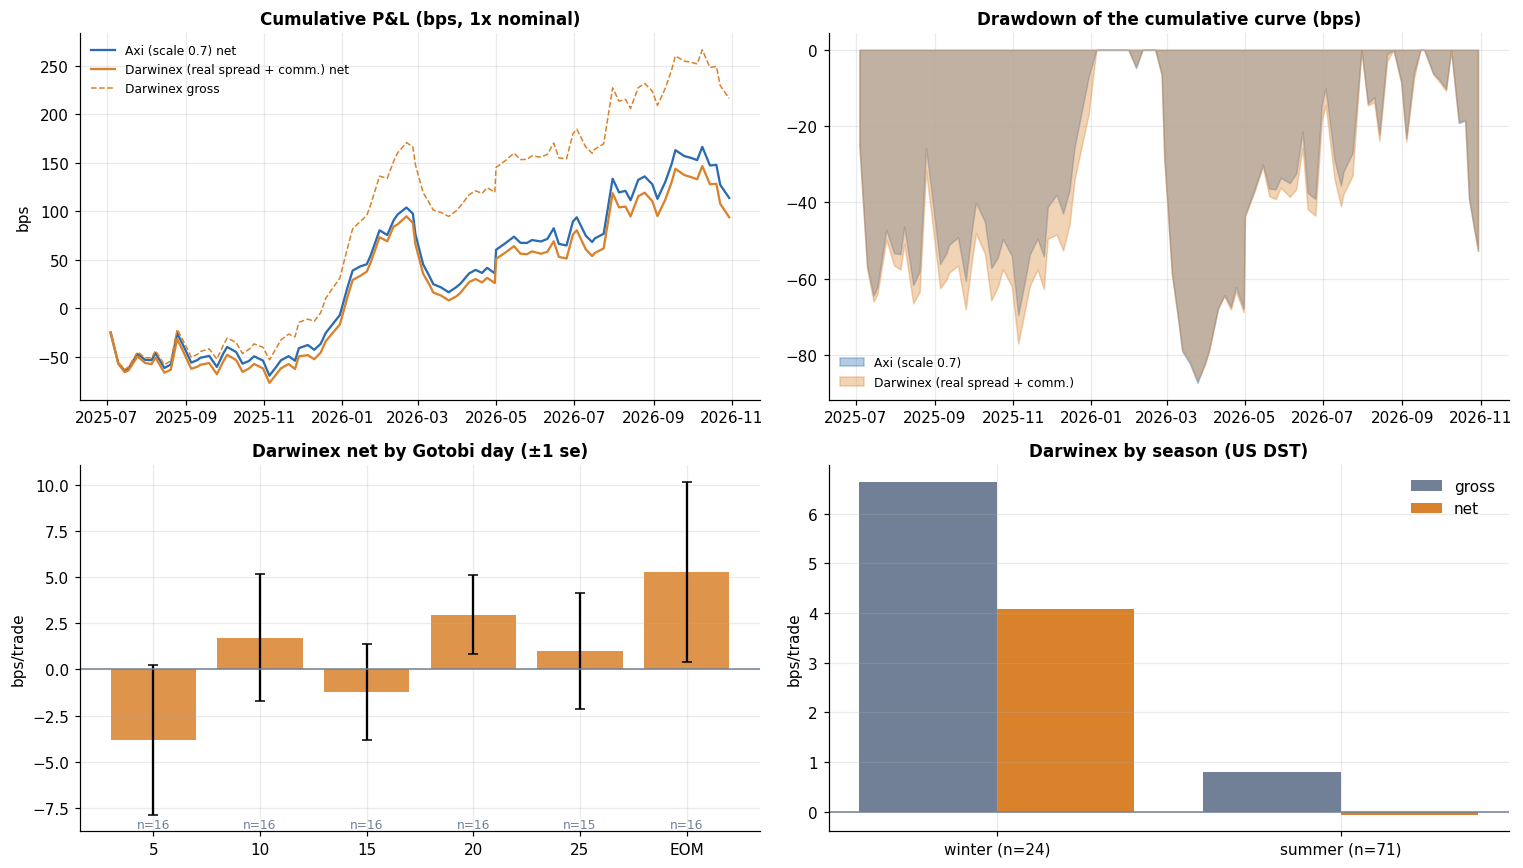

In [6]:
rows = {}
for k in TR:
    rows[f"{k} gross"] = eng.trade_stats(TR[k], "pnl_gross_bps")
    rows[f"{k} net"] = eng.trade_stats(TR[k], "pnl_bps")
ST = pd.DataFrame(rows).T[["n", "mean_bps", "median_bps", "std_bps", "t", "p_one", "pf", "win_rate", "sum_bps"]]
display(ST.round(3))

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for k in T:
    c = T[k]["pnl_bps"].cumsum()
    ax[0, 0].plot(c.index, c, color=COL[k], label=NAME[k] + " net")
    ax[0, 1].fill_between(c.index, c - np.maximum(c.cummax(), 0), 0, color=COL[k], alpha=.35, label=NAME[k])
ax[0, 0].plot(T["dwx"]["pnl_gross_bps"].cumsum(), color=DWX_C, ls="--", lw=1, label="Darwinex gross")
ax[0, 0].set(title="Cumulative P&L (bps, 1x nominal)", ylabel="bps"); ax[0, 0].legend(fontsize=8)
ax[0, 1].set(title="Drawdown of the cumulative curve (bps)"); ax[0, 1].legend(fontsize=8)

order = ["5", "10", "15", "20", "25", "EOM"]
g = T["dwx"].groupby("label")["pnl_bps"].agg(["mean", "std", "count"]).reindex(order)
ax[1, 0].bar(order, g["mean"], yerr=g["std"] / np.sqrt(g["count"]), color=DWX_C, alpha=.85, capsize=3)
for i, (o, n_) in enumerate(zip(order, g["count"])):
    ax[1, 0].text(i, ax[1, 0].get_ylim()[0], f"n={int(n_)}", ha="center", va="bottom", fontsize=8, color=GREY)
ax[1, 0].axhline(0, color=GREY, lw=1); ax[1, 0].set(title="Darwinex net by Gotobi day (±1 se)", ylabel="bps/trade")

w = np.arange(2); sea = ["winter", "summer"]
gm = [T["dwx"].loc[T["dwx"]["season"] == s, "pnl_gross_bps"].mean() for s in sea]
nm = [T["dwx"].loc[T["dwx"]["season"] == s, "pnl_bps"].mean() for s in sea]
cnt = [int((T["dwx"]["season"] == s).sum()) for s in sea]
ax[1, 1].bar(w - .2, gm, .4, color=GREY, label="gross"); ax[1, 1].bar(w + .2, nm, .4, color=DWX_C, label="net")
ax[1, 1].set_xticks(w); ax[1, 1].set_xticklabels([f"{s} (n={c})" for s, c in zip(sea, cnt)]); ax[1, 1].axhline(0, color=GREY, lw=1)
ax[1, 1].set(title="Darwinex by season (US DST)", ylabel="bps/trade"); ax[1, 1].legend()
plt.show()

## 5. SPECIFICITY · PLACEBO DATES, RANDOM DATES AND INTRADAY PROFILE
Is the window specific to Gotobi dates? In ~95 trades the answer is weak by construction; the point is to see whether Darwinex behaves like Axi, not to settle it.

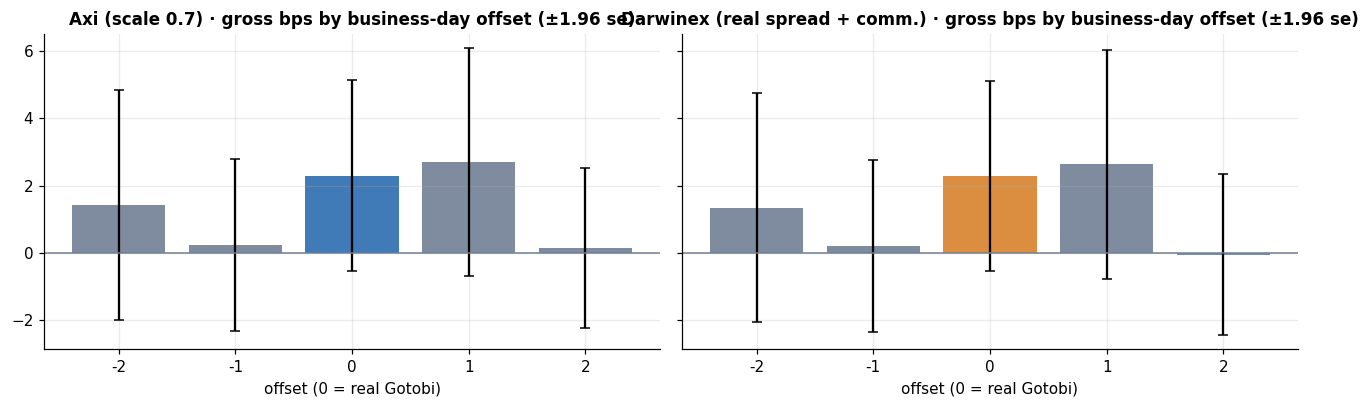

axi                                         dwx                    \
         n gross_bps gross_t net_bps  net_t pf_net   n gross_bps gross_t   
offset                                                                     
 0      95     2.290   1.583   1.196  0.840  1.260  95     2.277   1.580   
-2      96     1.426   0.821   0.267  0.155  1.051  96     1.344   0.774   
-1      96     0.238   0.184  -0.872 -0.669  0.828  96     0.213   0.163   
 1      96     2.691   1.560   1.497  0.877  1.309  96     2.628   1.515   
 2      95     0.154   0.128  -0.972 -0.789  0.805  95    -0.047  -0.039   

                              
       net_bps  net_t pf_net  
offset                        
 0       0.986  0.693  1.210  
-2      -0.085 -0.050  0.984  
-1      -1.128 -0.863  0.783  
 1       1.179  0.689  1.237  
 2      -1.389 -1.124  0.731

,exclude_neighbors=0,exclude_neighbors=1
n,95.0000,95.0000
n_control,228.0000,50.0000
real_mean_bps,2.2766,2.2766
control_mean_bps,0.6598,-0.5885
sim_mean_bps,0.6976,-0.5866
sim_sd_bps,1.1614,1.4569
z,1.3595,1.9653
p_one,0.0850,0.0218


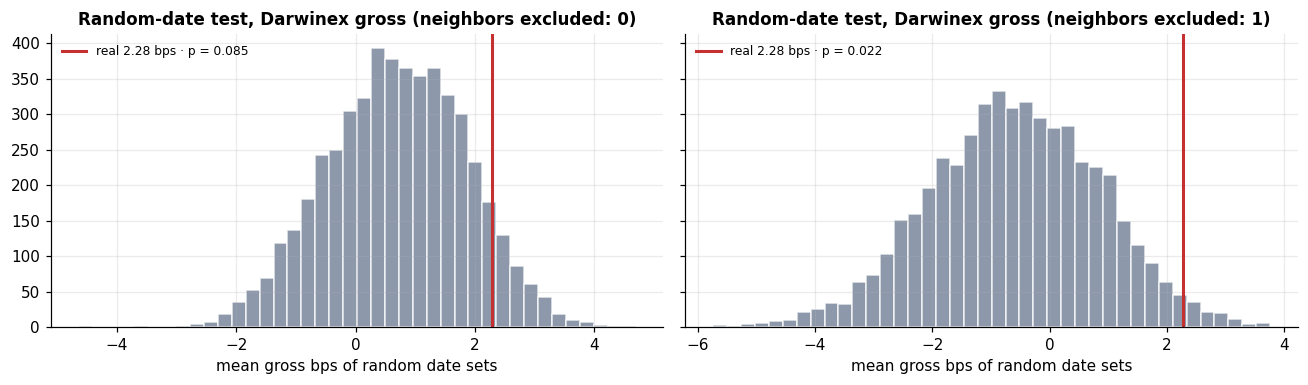

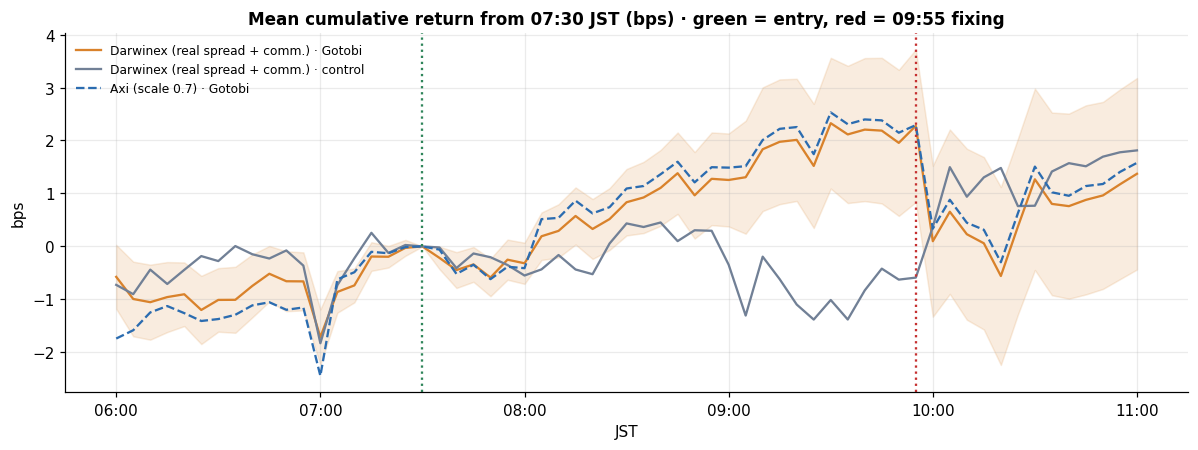

In [7]:
PL = {k: eng.placebo_table(DF[k], offsets=(-2, -1, 1, 2), **BT[k]) for k in DF}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, k in zip(ax, PL):
    p = PL[k].sort_index()
    se = (p["gross_bps"] / p["gross_t"]).abs().replace([np.inf, -np.inf], np.nan).fillna(0)
    a.bar(p.index.astype(str), p["gross_bps"], yerr=1.96 * se, capsize=3, color=[COL[k] if o == 0 else GREY for o in p.index], alpha=.9)
    a.axhline(0, color=GREY, lw=1); a.set(title=f"{NAME[k]} · gross bps by business-day offset (±1.96 se)", xlabel="offset (0 = real Gotobi)")
plt.show()
display(pd.concat(PL, axis=1).round(3))

# exclude_neighbors=2 empties the control (Gotobi dates are ~5 business days apart), so use 0 and 1
RT = {nb: eng.random_date_test(DF["dwx"], n_draws=N_PERM, seed=SEED, exclude_neighbors=nb) for nb in (0, 1)}
display(pd.DataFrame({f"exclude_neighbors={nb}": {k: v for k, v in r.items() if k != "sims"} for nb, r in RT.items()}).round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, (nb, r) in zip(ax, RT.items()):
    a.hist(r["sims"], bins=40, color=GREY, alpha=.8, edgecolor="white")
    a.axvline(r["real_mean_bps"], color=RED, lw=2, label=f"real {r['real_mean_bps']:.2f} bps · p = {r['p_one']:.3f}")
    a.set(title=f"Random-date test, Darwinex gross (neighbors excluded: {nb})", xlabel="mean gross bps of random date sets"); a.legend(fontsize=8)
plt.show()

a_, b_ = (DF["dwx"].index[0] + eng.JST).normalize(), (DF["dwx"].index[-1] + eng.JST).normalize()
gd = eng.gotobi_calendar(a_, b_).index
cd = eng.control_dates(a_, b_, exclude_neighbors=1)
PROF = {("dwx", "Gotobi"): eng.intraday_profile(DF["dwx"], gd, "06:00", "11:00", ET),
        ("dwx", "control"): eng.intraday_profile(DF["dwx"], cd, "06:00", "11:00", ET),
        ("axi", "Gotobi"): eng.intraday_profile(DF["axi"], gd, "06:00", "11:00", ET)}
fig, ax = plt.subplots(figsize=(11, 4.2))
sty = {("dwx", "Gotobi"): (DWX_C, "-"), ("dwx", "control"): (GREY, "-"), ("axi", "Gotobi"): (AXI_C, "--")}
for key, p in PROF.items():
    c, ls = sty[key]; x = np.arange(len(p))
    ax.plot(x, p["mean_cum_bps"], color=c, ls=ls, label=f"{NAME[key[0]]} · {key[1]}")
    if key == ("dwx", "Gotobi"):
        ax.fill_between(x, p["mean_cum_bps"] - p["se_cum_bps"], p["mean_cum_bps"] + p["se_cum_bps"], color=c, alpha=.15)
idx = list(PROF[("dwx", "Gotobi")].index)
ax.axvline(idx.index(ET), color=GREEN, ls=":"); ax.axvline(idx.index(XT), color=RED, ls=":")
ax.set_xticks(range(0, len(idx), 12)); ax.set_xticklabels(idx[::12])
ax.set(title="Mean cumulative return from 07:30 JST (bps) · green = entry, red = 09:55 fixing", xlabel="JST", ylabel="bps"); ax.legend(fontsize=8)
plt.show()

## 6. CONTEXT · WHERE DOES THIS WINDOW SIT IN THE AXI HISTORY?
The Darwinex window is also the last stretch of the Axi series (not independent), so this only shows whether it looks unusual. Gross returns are used because they are comparable across feeds; the long-history net uses a flat spread (the feed spread is not real before 2021).

,n,gross_bps,net_bps,net_t,pf,se_gross
year,,,,,,
2017,71,5.680,4.788,2.701,2.413,1.773
2018,71,2.133,1.227,0.729,1.270,1.683
2019,70,2.620,1.702,1.286,1.507,1.324
2020,70,4.498,3.560,1.354,1.728,2.630
2021,71,3.502,2.590,2.644,2.335,0.980
2022,72,4.267,3.501,1.543,1.606,2.269
2023,71,3.506,2.792,1.172,1.498,2.382
2024,71,2.887,2.226,0.941,1.353,2.364
2025,70,1.340,0.670,0.339,1.109,1.976


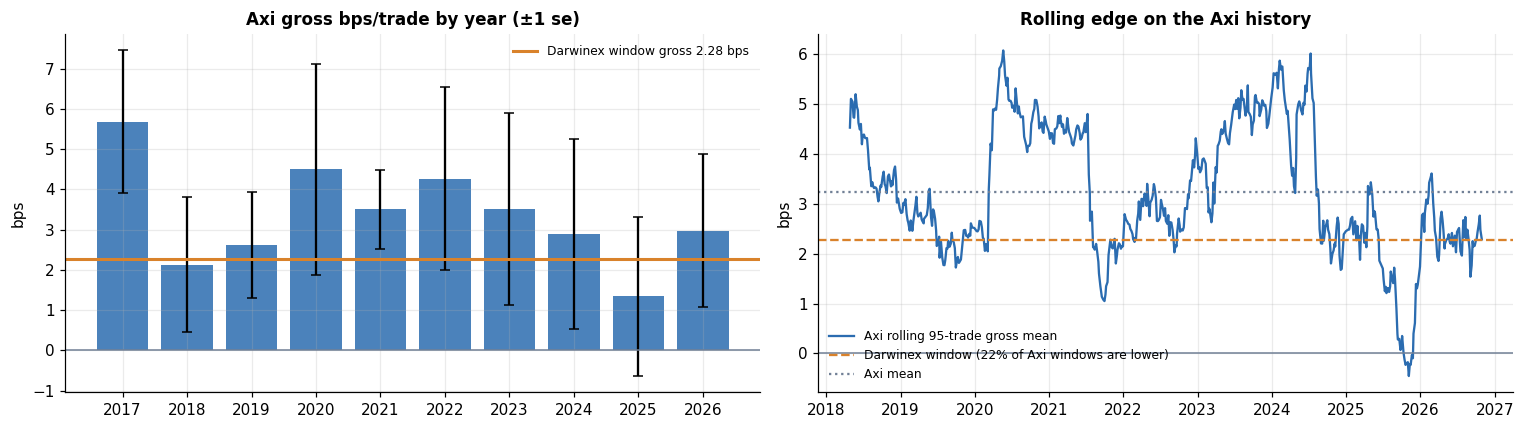

In [8]:
FULL = TF = None
if AXI_FULL_START:
    FULL = eng.load_data(csv_path=AXI_CSV, start=AXI_FULL_START, verbose=False)
    TF = eng.run_gotobi_backtest(FULL, cost_mode="flat_pips", flat_spread_pips=CTX_FLAT_PIPS, commission_bps_per_side=COMM_AXI)
    TF["year"] = pd.to_datetime(TF["entry_date"]).dt.year
    yrs = []
    for y, g in TF.groupby("year"):
        s = eng.trade_stats(g, "pnl_bps")
        yrs.append(dict(year=y, n=s["n"], gross_bps=g["pnl_gross_bps"].mean(), net_bps=s["mean_bps"], net_t=s["t"], pf=s["pf"],
                        se_gross=g["pnl_gross_bps"].std(ddof=1) / np.sqrt(len(g))))
    yrs = pd.DataFrame(yrs).set_index("year")
    display(yrs.round(3))

    N = len(TR["dwx"]); dwx_g = TR["dwx"]["pnl_gross_bps"].mean()
    roll = TF.set_index(pd.to_datetime(TF["entry_date"]))["pnl_gross_bps"].rolling(N).mean().dropna()
    pct = float((roll < dwx_g).mean())
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].bar(yrs.index.astype(str), yrs["gross_bps"], yerr=yrs["se_gross"], capsize=3, color=AXI_C, alpha=.85)
    ax[0].axhline(dwx_g, color=DWX_C, lw=2, label=f"Darwinex window gross {dwx_g:.2f} bps"); ax[0].axhline(0, color=GREY, lw=1)
    ax[0].set(title="Axi gross bps/trade by year (±1 se)", ylabel="bps"); ax[0].legend(fontsize=8)
    ax[1].plot(roll.index, roll, color=AXI_C, label=f"Axi rolling {N}-trade gross mean")
    ax[1].axhline(dwx_g, color=DWX_C, lw=1.5, ls="--", label=f"Darwinex window ({pct:.0%} of Axi windows are lower)")
    ax[1].axhline(roll.mean(), color=GREY, ls=":", label="Axi mean"); ax[1].axhline(0, color=GREY, lw=1)
    ax[1].set(title="Rolling edge on the Axi history", ylabel="bps"); ax[1].legend(fontsize=8)
    plt.show()
else:
    print("AXI_FULL_START = None: section skipped.")

## 7. EXPLORATORY · ENTRY SPREAD FILTER (NOT ADOPTED)

> The cost tail is a **winter** effect (the entry is only 30 min after the rollover). A cap on the entry spread could raise the net edge, but it is a **new hypothesis**: if pursued it adds 1 to `hypotheses_tested` (17 → 18) and must be decided on the long Axi sample (7b), never on these ~95 trades (7a). Nothing here changes the rules.

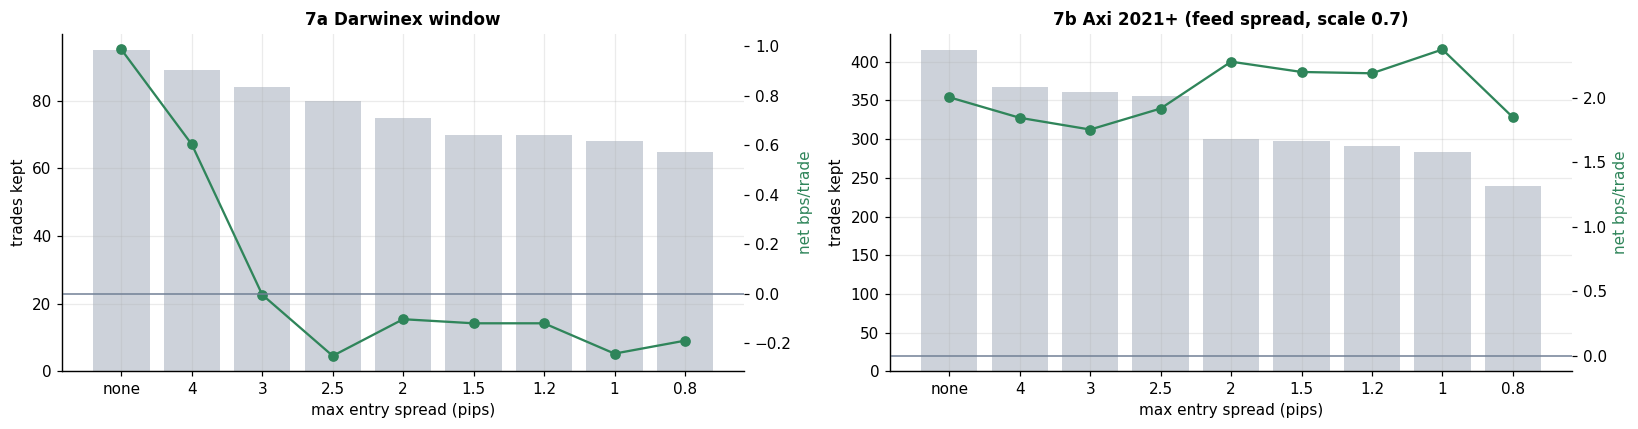

7a Darwinex window


,cap_pips,n,net_bps,t,pf
0,inf,95,0.986,0.693,1.210
1,4.0,89,0.603,0.415,1.127
2,3.0,84,-0.004,-0.002,0.999
3,2.5,80,-0.250,-0.163,0.951
4,2.0,75,-0.102,-0.063,0.980
5,1.5,70,-0.119,-0.071,0.977
6,1.2,70,-0.119,-0.071,0.977
7,1.0,68,-0.241,-0.141,0.954
8,0.8,65,-0.189,-0.106,0.965


7b Axi 2021+ (feed spread, scale 0.7)


,cap_pips,n,net_bps,t,pf
0,inf,415,2.004,2.418,1.389
1,4.0,368,1.845,2.090,1.359
2,3.0,361,1.754,1.969,1.340
3,2.5,356,1.917,2.173,1.384
4,2.0,300,2.280,2.385,1.468
5,1.5,297,2.200,2.289,1.448
6,1.2,291,2.190,2.234,1.438
7,1.0,283,2.374,2.377,1.481
8,0.8,240,1.849,1.666,1.352


In [9]:
CAPS = [np.inf, 4, 3, 2.5, 2, 1.5, 1.2, 1.0, 0.8]
def cap_table(df, **kw):
    rows = []
    for c in CAPS:
        s = eng.trade_stats(eng.run_gotobi_backtest(df, max_entry_spread_pips=c, **kw))
        rows.append(dict(cap_pips=c, n=s["n"], net_bps=s["mean_bps"], t=s["t"], pf=s["pf"]))
    return pd.DataFrame(rows)

CT = {"7a Darwinex window": cap_table(DF["dwx"], **BT["dwx"])}
if FULL is not None:
    CT["7b Axi 2021+ (feed spread, scale 0.7)"] = cap_table(FULL[FULL.index >= "2021-01-01"], **BT["axi"])
fig, ax = plt.subplots(1, len(CT), figsize=(7.5 * len(CT), 4), squeeze=False)
for a, (name, ct) in zip(ax[0], CT.items()):
    lab = ["none" if np.isinf(c) else f"{c:g}" for c in ct["cap_pips"]]
    a.bar(lab, ct["n"], color=GREY, alpha=.35); a.set(title=name, xlabel="max entry spread (pips)", ylabel="trades kept")
    a2 = a.twinx(); a2.plot(lab, ct["net_bps"], color=GREEN, marker="o"); a2.set_ylabel("net bps/trade", color=GREEN); a2.grid(False)
    a2.axhline(0, color=GREY, lw=1)
plt.show()
for name, ct in CT.items():
    print(name); display(ct.round(3))

## 8. SIZING AND RISK AT THE DECLARED FRACTION
`hard_limit` and `size_fraction` are the Axi Select numbers. Darwinex measures risk through the DARWIN's VaR, which is **not modelled here**: define that limit separately before fixing the size. Below, the drawdown and lots implied by the same fraction.

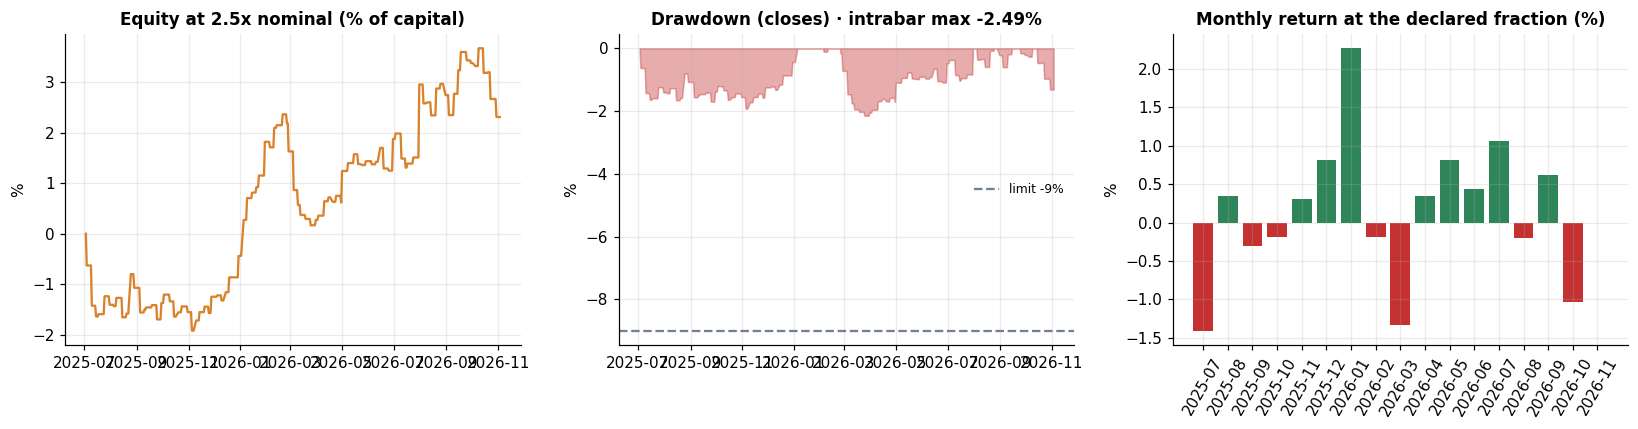

Total return 2.31% | max DD intrabar -2.49% (headroom 6.51%) | worst month -1.41% | monthly sd 0.91%
Max fraction that respects -9% on this window: 9.27x (declared 2.5x)
Lots at 10,000 USD: min 0.24 · max 0.25 | min capital for the target fraction: 400 USD


In [10]:
tr = TR["dwx"]; df = DF["dwx"]
dr = eng.daily_returns(df, tr, FRAC)
eq = (1 + dr).cumprod()
ddc = eq / np.maximum(eq.cummax(), 1) - 1
rep = eng.hard_limit_report_intrabar(df, tr, HARD, FRAC)
mf = eng.max_fraction_for_limit(df, tr, HARD)
sizes = eng.cfd_trade_sizes(tr, CAPITAL, FRAC)
mon = dr.groupby(dr.index.to_period("M")).apply(lambda x: (1 + x).prod() - 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(eq.index, (eq - 1) * 100, color=DWX_C); ax[0].set(title=f"Equity at {FRAC:g}x nominal (% of capital)", ylabel="%")
ax[1].fill_between(ddc.index, ddc * 100, 0, color=RED, alpha=.4); ax[1].axhline(-HARD * 100, color=GREY, ls="--", label=f"limit -{HARD:.0%}")
ax[1].set(title=f"Drawdown (closes) · intrabar max {rep['max_dd']:.2%}", ylabel="%"); ax[1].legend(fontsize=8)
ax[2].bar(mon.index.astype(str), mon * 100, color=[GREEN if v > 0 else RED for v in mon]); ax[2].tick_params(axis="x", rotation=60)
ax[2].set(title="Monthly return at the declared fraction (%)", ylabel="%")
plt.show()
print(f"Total return {eq.iloc[-1] - 1:.2%} | max DD intrabar {rep['max_dd']:.2%} (headroom {rep['headroom']:.2%}) | worst month {mon.min():.2%} | monthly sd {mon.std():.2%}")
print(f"Max fraction that respects -{HARD:.0%} on this window: {mf:.2f}x (declared {FRAC:g}x)")
print(f"Lots at {CAPITAL:,.0f} USD: min {sizes['lots'].min():.2f} · max {sizes['lots'].max():.2f} | min capital for the target fraction: {eng.min_capital_for_target(tr['entry_price'].mean(), FRAC):,.0f} USD")

## 9. VERDICT, OPEN ITEMS AND OUTPUTS

In [11]:
val_ok = bool(chk["dwx"]["all_ok"])
gates = [("Engine quality gate (Darwinex)", val_ok),
         ("Weekly structure >= 99% (time conversion)", chk["dwx"]["weekly_ok_share"] >= .99),
         ("Same trade dates in both feeds", da == dd_),
         (f"Gross correlation >= {CORR_MIN}", PAIR["corr"] >= CORR_MIN),
         (f"|mean gross diff| <= {MAX_MEAN_DIFF_BPS} bps", abs(PAIR["mean_diff_bps"]) <= MAX_MEAN_DIFF_BPS),
         (f"sd of gross diff <= {MAX_SD_DIFF_BPS} bps", PAIR["sd_diff_bps"] <= MAX_SD_DIFF_BPS)]
for name, ok in gates:
    print(("PASS  " if ok else "FAIL  ") + name)
REPLICATES = all(ok for _, ok in gates)
print("\nREPLICATION:", "OK, Darwinex executes the same trade as Axi" if REPLICATES else "NOT OK, review the failed gates")

nd, na = ST.loc["dwx net"], ST.loc["axi net"]
print("\nINFORMATIONAL (not gates)")
print(f"  Net bps/trade   Darwinex {nd['mean_bps']:.2f} (t {nd['t']:.2f}, PF {nd['pf']:.2f}) | Axi {na['mean_bps']:.2f} (t {na['t']:.2f}, PF {na['pf']:.2f})")
print(f"  Cost share of gross: Darwinex {dec.loc['dwx', 'cost_share_of_gross']:.0%} | Axi (placeholder) {dec.loc['axi', 'cost_share_of_gross']:.0%}")
print(f"  Break-even flat spread: Darwinex {BE['dwx']:.2f} pips vs mean paid {TR['dwx']['spread_pips'].mean():.2f} ({BE['dwx'] / TR['dwx']['spread_pips'].mean():.1f}x; v1 acceptance asks >= 2x)")
print(f"  Random-date p (Darwinex gross): {RT[0]['p_one']:.3f} | placebo +1 day gross {PL['dwx'].loc[1, 'gross_bps']:.2f} bps vs real {PL['dwx'].loc[0, 'gross_bps']:.2f}")

open_items = ["Confirm whether the Darwinex commission (2.5 USD/lot) is per deal (0.25 bps/side) or per round trip",
              "Bars with feed spread = 0 at entry: check whether Darwinex really quoted 0 at 22:30 UTC",
              "Darwinex risk limit (DARWIN VaR) is not modelled: define it before fixing size_fraction",
              "Net edge is ~1 bp/trade after costs: a spread filter (section 7) needs its own hypothesis count and the Axi long sample"]
print("\nOPEN ITEMS"); [print("  -", o) for o in open_items]

if WRITE_OUTPUTS:
    run_dir = EDGE_DIR / "runs" / "GOTOBI.usdjpy.cfd.v2_darwinex"; run_dir.mkdir(parents=True, exist_ok=True)
    J.to_csv(run_dir / "paired_trades_axi_vs_darwinex.csv")
    summary = dict(window=[str(DF["dwx"].index[0]), str(END)], replicates=bool(REPLICATES), paired=PAIR,
                   net={k: {x: float(v) for x, v in ST.loc[f"{k} net"].items()} for k in ("axi", "dwx")},
                   costs=dec.round(4).to_dict(orient="index"), breakeven_pips={k: float(v) for k, v in BE.items()},
                   random_date_p=float(RT[0]["p_one"]), open_items=open_items)
    (run_dir / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
    print("\nsaved to", run_dir)

YAML = "\n".join([
    "id: GOTOBI.usdjpy.cfd.v1", "variant: v2_darwinex_usdjpy",
    "description: >", "  Gotobi on USDJPY, Darwinex replication of v1_axi_usdjpy. Same FIXED rules. Short sample: replication check only.",
    "instrument:", "  symbol: USDJPY", "  broker: Darwinex", '  start: "2025-07-02"', "  end: null",
    "  data_csv: " + DWX_CSV, "  time_mode: mt5_server_ny",
    "account:", "  capital: 10000", "  ccy: USD", "  cfd_preset: axi_usdjpy   # same contract spec (100k, 0.01 lot)",
    "costs:", "  cost_mode: feed", "  spread_scale: 1.0          # real Darwinex spread",
    f"  commission_bps_per_side: {COMM_DWX}   # 2.5 USD/lot per deal (verify per side vs round trip)",
    "evidence_thresholds:", "  hypotheses_tested: 17      # same rule, new broker: no new hypothesis",
    "risk: { hard_limit: null, size_fraction: null }   # define from the Darwinex VaR limit",
    "open_items:"] + ["  - " + o for o in open_items])
if WRITE_YAML and (EDGE_DIR / "variants").is_dir():
    (EDGE_DIR / "variants" / "v2_darwinex_usdjpy.yaml").write_text(YAML + "\n"); print("draft YAML written")
else:
    print("\nDRAFT YAML (WRITE_YAML=False):\n" + YAML)

PASS  Engine quality gate (Darwinex)
PASS  Weekly structure >= 99% (time conversion)
PASS  Same trade dates in both feeds
PASS  Gross correlation >= 0.99
PASS  |mean gross diff| <= 0.5 bps
PASS  sd of gross diff <= 2.0 bps

REPLICATION: OK, Darwinex executes the same trade as Axi

INFORMATIONAL (not gates)
  Net bps/trade   Darwinex 0.99 (t 0.69, PF 1.21) | Axi 1.20 (t 0.84, PF 1.26)
  Cost share of gross: Darwinex 57% | Axi (placeholder) 48%
  Break-even flat spread: Darwinex 2.76 pips vs mean paid 1.23 (2.2x; v1 acceptance asks >= 2x)
  Random-date p (Darwinex gross): 0.085 | placebo +1 day gross 2.63 bps vs real 2.28

OPEN ITEMS
  - Confirm whether the Darwinex commission (2.5 USD/lot) is per deal (0.25 bps/side) or per round trip
  - Bars with feed spread = 0 at entry: check whether Darwinex really quoted 0 at 22:30 UTC
  - Darwinex risk limit (DARWIN VaR) is not modelled: define it before fixing size_fraction
  - Net edge is ~1 bp/trade after costs: a spread filter (section 7) nee